# Reproduce the retained public-0.40 submission

**Peilin Li — Nankai University**  
Contact: 2510547@mail.nankai.edu.cn

This Notebook performs fresh inference from the official 180 test images using the five supplied weight files. With the default `RUN_TRAINING = False`, it does not train models, read annotations, use prediction caches, or fetch model weights. A separate optional training branch is provided below. The original submission is accessed only by the final verification cell.

The displayed public score was reported as **0.40**; the exact unrounded score and private score are unknown. This is not an independent local PQ evaluation.

Install `requirements.txt` in Python 3.14.7 with an NVIDIA CUDA-capable environment, clone with all Git LFS model objects, then run all cells. The verified environment is Windows / RTX 5090 / CUDA 13.0. See README for portability limits and upstream attribution.

## 1. Set the image directory

Set `SFSEG_TEST_DIR` to the folder containing the official test JPEGs, or edit the default below. Dataset access/competition acceptance remains with the participant. No training JSON or test labels are needed. A new output directory is used on every run.

In [1]:
import os
from pathlib import Path
from datetime import datetime

ROOT = Path.cwd().resolve()
assert (ROOT / "sfseg/reproduce.py").is_file(), "Open the Notebook from the repository root"
TEST_DIR = Path(os.environ.get("SFSEG_TEST_DIR", "data/test_images")).resolve()
OUTPUT_DIR = ROOT / "outputs" / ("notebook-" + datetime.now().strftime("%Y%m%d-%H%M%S"))
assert TEST_DIR.is_dir(), "Set SFSEG_TEST_DIR or edit TEST_DIR"
print("Input image directory found; output:", OUTPUT_DIR.relative_to(ROOT))
import sys
print("Python:", sys.version)
print("Environment:", sys.prefix)
print("Isolated venv:", sys.prefix != sys.base_prefix)

Input image directory found; output: outputs\notebook-20261114-122219
Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Environment: C:\Users\ROG\Documents\ChatGPT\比赛\tmp\final-submission-clean-env-20261114
Isolated venv: True


## 2. Optional training (disabled by default)

The normal reproduction path loads the five supplied models and frozen calibration maps. Leave `RUN_TRAINING = False` to reproduce the submitted CSV without training.

The optional path is implemented in `sfseg/train.py` and `sfseg/training/`. It verifies the official **training** JSON and image hashes; prepares isolated date/hash routes; trains seven Base models (each 9,216 updates), four residual refiners (each 4,992 updates), and two 192-feature HistGBDT regressors from excluded-fold candidates; then trains the A451 YOLO branch (up to 40 epochs) and the A451 grayscale crop refiner (15 epochs). Independent expert annotations are retained. Only generic, hash-checked initialization is downloaded.

To intentionally train a new bundle, set the switch below to `True`, supply `SFSEG_TRAIN_DATA` and a **new external** `SFSEG_TRAIN_OUTPUT` folder. This is expensive and requires at least 150 GiB free. The release weights are never overwritten. The newly trained bundle flows into the same inference code. Source/conditional calibration maps and thresholds stay fixed to the retained recipe; this path does not claim that a fresh training run reproduces the historical weights or CSV bytes. See `TRAINING.md` for scope and provenance.

For this release update, only import, data/routing, and disabled-gate checks were run; **no optimizer updates or model training were performed**.

In [2]:
from sfseg.train import training_plan, execute_training

RUN_TRAINING = False
MODEL_DIR = ROOT / "models"
plan = training_plan()  # pure configuration/routing validation; no model initialization
print({k: plan[k] for k in ["physical_images", "base_updates_each", "refiner_updates_each", "detector_roles"]})
if RUN_TRAINING:
    train_data = os.environ.get("SFSEG_TRAIN_DATA")
    train_output = os.environ.get("SFSEG_TRAIN_OUTPUT")
    assert train_data and train_output, "Set training data and a new external output directory"
    MODEL_DIR = execute_training(train_data, train_output, enabled=True)
else:
    print("Training disabled: loading supplied weights; optimizer updates = 0.")

{'physical_images': 707, 'base_updates_each': 9216, 'refiner_updates_each': 4992, 'detector_roles': {'calibration': 57, 'fit': 451, 'selection': 57, 'validation': 142}}
Training disabled: loading supplied weights; optimizer updates = 0.


## 3. Verify model identity

The manifest binds every checkpoint and the two-regressor pickle. Only these trusted, hash-checked files are deserialized. The Base and refiner instantiate with no automatic ImageNet download.

In [3]:
from sfseg.reproduce import verify_models, run, verify
weights = verify_models(MODEL_DIR)
print("Verified", len(weights), "model files")
print("Model size: %.2f MiB" % (sum(r["bytes"] for r in weights.values()) / 1024**2))

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\ROG\Documents\ChatGPT\\deliverables\final-submission-public-20261114\.runtime\yolo\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


C:\Users\ROG\Documents\ChatGPT\比赛\tmp\final-submission-clean-env-20261114\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Verified 5 model files
Model size: 493.60 MiB


## 4. Full inference: images → Base masks → quality filter → protected supplements → CSV

- Native 2048 Base forward pass, original connected-component rules.
- Residual mask refinement; 192 image/mask features; two tree outputs multiplied; fixed 0.10 threshold.
- Fresh YOLO boxes at 1280; grayscale ResNet34 crop refinement with the frozen four-flip policy.
- Frozen source calibration, NMS, Base protection, painting, and conditional calibration.
- Encode each surviving non-overlapping instance as compressed COCO RLE.

No reference prediction is passed to `run`. This cell performs the entire pipeline, not a cached-CSV copy.

In [4]:
manifest = run(TEST_DIR, OUTPUT_DIR, model_dir=MODEL_DIR)
print({k: manifest[k] for k in ["instances", "base_instances", "supplement_instances", "elapsed_seconds", "peak_allocated_vram_gib", "submission_sha256"]})

{"images": 10, "total": 180, "elapsed_seconds": 29.7}


{"images": 20, "total": 180, "elapsed_seconds": 47.3}


{"images": 30, "total": 180, "elapsed_seconds": 66.0}


{"images": 40, "total": 180, "elapsed_seconds": 83.0}


{"images": 50, "total": 180, "elapsed_seconds": 102.0}


{"images": 60, "total": 180, "elapsed_seconds": 118.5}


... (9 outputs left out)

{"images": 160, "total": 180, "elapsed_seconds": 262.2}


{"images": 170, "total": 180, "elapsed_seconds": 272.1}


{"images": 180, "total": 180, "elapsed_seconds": 285.8}


{'instances': 1261, 'base_instances': 1220, 'supplement_instances': 41, 'elapsed_seconds': 285.8533364, 'peak_allocated_vram_gib': 2.1991634368896484, 'submission_sha256': '16a9b935222168d93cb106e7939a763732d259ee165fc2ebd870fda157f48957'}


## 5. Independent output comparison

Only now is the retained reference CSV read. Verify all 180 image entries, nonempty/non-overlapping masks, consecutive IDs, RLE round trips, per-instance identity, and the complete file SHA256.

In [5]:
if not RUN_TRAINING:
    checks = verify(OUTPUT_DIR)
    assert checks["passed"] and checks["full_test_set"] and checks["byte_identical_to_reference"]
    print("PASS: 180 images, 1,261 instances, byte-identical CSV.")
else:
    print("Freshly trained bundle: reference parity is not claimed; inspect inference-manifest.json.")

{
  "passed": true,
  "full_test_set": true,
  "images": 180,
  "instances": 1261,
  "exact_instance_RLE": true,
  "nonempty_nonoverlapping": true,
  "byte_identical_to_reference": true,
  "submission_sha256": "16a9b935222168d93cb106e7939a763732d259ee165fc2ebd870fda157f48957",
  "reference_used_only_after_inference": true
}
PASS: 180 images, 1,261 instances, byte-identical CSV.


## 6. Inspect predictions (no test ground truth)

Cyan is the Base branch; orange is the additive detector branch. The first image in the frozen test order is shown without performance-based selection.

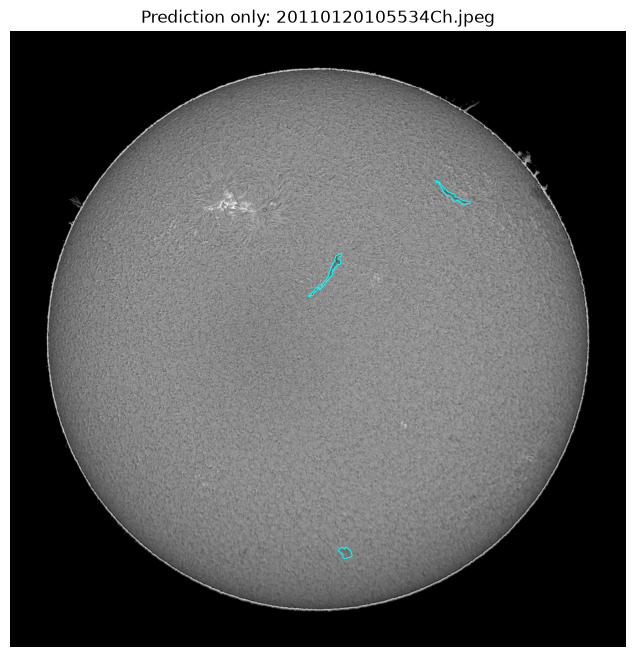

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pycocotools.mask as mu
from sfseg.reproduce import groups

row = manifest["images"][0]
raw = np.asarray(Image.open(TEST_DIR / row["file_name"]).convert("L"))
rles = groups(OUTPUT_DIR / "submission.csv").get(Path(row["file_name"]).stem, [])
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(raw, cmap="gray", vmin=0, vmax=255)
for i, rle in enumerate(rles):
    mask = mu.decode({"size": [2048, 2048], "counts": rle.encode()})
    ax.contour(mask, levels=[0.5], colors=["cyan" if i < row["base_instances"] else "orange"], linewidths=0.7)
ax.set_title("Prediction only: " + row["file_name"])
ax.axis("off")
plt.show()

## Output and interpretation

`OUTPUT_DIR/submission.csv` is the regenerated submission. The adjacent inference manifest records hashes, environment, runtime and VRAM; `verification.json` records parity checks. Exact reproduction on other hardware or dependency versions must be checked rather than assumed. No Kaggle upload or repository publication is performed by this Notebook.